# Build a curious rocket

A hands-on session on cpomdp, continuous active inference in Python. You build three
rockets. The first is the 1960 controller, a Kalman filter with a goal. In the last,
three rockets fly past a rock none of them was told about.

Run the cells in order. Each task has an attempt cell with two lines for you to write,
two hints and a collapsed reference cell. Using the reference is fine. The checkpoint
after each task puts the reference names in place, so a task that went wrong costs
nothing later.

Ask anonymously on the form (link to come).

In [1]:
# Installs the workshop on Colab, then checks the versions it was measured on.
import sys

if "google.colab" in sys.modules:
    !pip install -q cpomdp-workshop==0.1.0
import cpomdp_workshop as workshop

workshop.hello()

cpomdp 0.5.0, jax 0.11.1, Python 3.12.3. Ready.
launch (0.0, 0.0) -> pad (5.0, 0.0), nav beacon at (2.5, 1.4), blackout at (2.5, 0.0) with a rock of radius 0.42


*This is what you will have built by 1:32.*

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


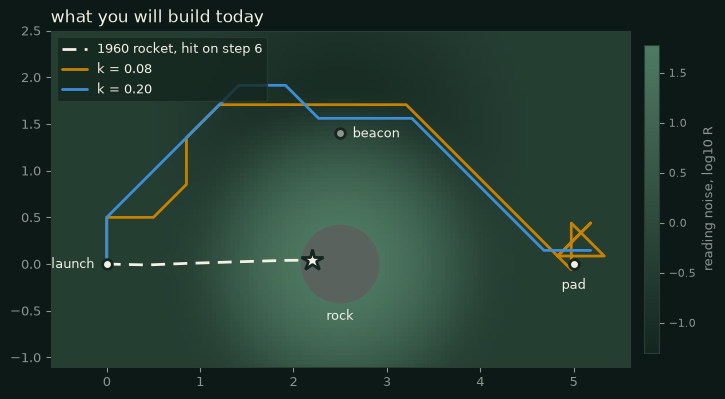

In [2]:
workshop.preview()

Missed the three questions at registration? They take thirty seconds: the pre-flight
form (link to come).

In [3]:
# @title Stuck on an error? The five most common, with their fixes
import cpomdp_workshop as workshop

workshop.symptoms()

1. a state-dependent sensor in the noise slot
   you wrote  LinearGaussianModel(I, observation_noise=sensor, control_matrix=I, dynamics_noise=1e-3 * I, prior=prior)
   cpomdp     TypeError: observation_noise takes a matrix, got CallableSensor, an ObservationModel. Pass it as observation_model.
   write      LinearGaussianModel(I, observation_model=sensor, control_matrix=I, dynamics_noise=1e-3 * I, prior=prior)

2. a goal beside a planner
   you wrote  Agent(curious_model, StateGoal(PAD), selector=planner)
   cpomdp     TypeError: selector= takes a Preference, the target and precision the selector chooses toward. Got StateGoal. A StateGoal or ObservationGoal configures the selector the Agent builds, so it goes without selector=.
   write      Agent(curious_model, Preference(PAD), selector=planner)



3. a state goal under a sensor that depends on the state
   you wrote  Agent(curious_model, StateGoal(PAD))
   cpomdp     ValueError: a StateGoal needs a fixed sensor. A state-dependent sensor would require converting the goal through C. Pass an ObservationGoal.
   write      Agent(curious_model, Preference(PAD), selector=planner)



4. a preference of the wrong length
   you wrote  Agent(curious_model, Preference([5.0, 0.0, 0.0]), selector=planner)
   cpomdp     ValueError: RecedingHorizonSelector reads the Preference's target as an observation, a vector of length 2, got shape (3,)
   write      Agent(curious_model, Preference([5.0, 0.0]), selector=planner)

5. swapping the model under a built rocket
   you wrote  rocket.model = model_with()
   cpomdp     AttributeError: property 'model' of 'Agent' object has no setter
   write      rocket = Agent(model_with(), pad_goal())



## Task 1 · the 1960 rocket

The rocket flies from the launch site to the pad. It reads its position through a
sensor whose noise is the same everywhere. That is the Kalman filter's world. LQR is
its controller.

Write the two `...` lines. The rest is written. `check_agent` prints the rocket you
built and flies it. Then `probe_model` asks cpomdp whether any of the nine compass
moves would teach the rocket more than another.

Then try to make it curious. Change the noise level, the prior's spread, the step
size or the goal, and probe again.

**Paste your spread in chat.**

In [ ]:
import jax.numpy as jnp
from cpomdp import Agent, Belief, LinearGaussianModel, StateGoal, probe_model

from cpomdp_workshop import LAUNCH, PAD, check_agent, compass_moves, show_probe

observation_matrix = ...  # C (pymdp's A): the reading sees the whole position
observation_noise = ...  # R: variance 0.05 on each axis, the same everywhere

model = LinearGaussianModel(
    jnp.eye(2),  # dynamics, pymdp's B: the rocket stays put unless moved
    control_matrix=jnp.eye(2),  # a move adds straight to the position
    observation_matrix=observation_matrix,
    observation_noise=observation_noise,
    dynamics_noise=1e-3 * jnp.eye(2),  # Q: a little drift each step
    prior=Belief(mean=LAUNCH, cov=4 * jnp.eye(2)),  # pymdp's D: unsure where it is
)
goal = StateGoal(PAD, precision=jnp.eye(2), effort=100 * jnp.eye(2))  # thruster cost
rocket = Agent(model, goal)
check_agent(rocket)

report = probe_model(model, model.prior, compass_moves())
show_probe(report)  # paste the spread in chat

In [4]:
# @title Stuck on an error? The five most common, with their fixes
import cpomdp_workshop as workshop

workshop.symptoms()

1. a state-dependent sensor in the noise slot
   you wrote  LinearGaussianModel(I, observation_noise=sensor, control_matrix=I, dynamics_noise=1e-3 * I, prior=prior)
   cpomdp     TypeError: observation_noise takes a matrix, got CallableSensor, an ObservationModel. Pass it as observation_model.
   write      LinearGaussianModel(I, observation_model=sensor, control_matrix=I, dynamics_noise=1e-3 * I, prior=prior)

2. a goal beside a planner
   you wrote  Agent(curious_model, StateGoal(PAD), selector=planner)
   cpomdp     TypeError: selector= takes a Preference, the target and precision the selector chooses toward. Got StateGoal. A StateGoal or ObservationGoal configures the selector the Agent builds, so it goes without selector=.
   write      Agent(curious_model, Preference(PAD), selector=planner)



3. a state goal under a sensor that depends on the state
   you wrote  Agent(curious_model, StateGoal(PAD))
   cpomdp     ValueError: a StateGoal needs a fixed sensor. A state-dependent sensor would require converting the goal through C. Pass an ObservationGoal.
   write      Agent(curious_model, Preference(PAD), selector=planner)

4. a preference of the wrong length
   you wrote  Agent(curious_model, Preference([5.0, 0.0, 0.0]), selector=planner)
   cpomdp     ValueError: RecedingHorizonSelector reads the Preference's target as an observation, a vector of length 2, got shape (3,)
   write      Agent(curious_model, Preference([5.0, 0.0]), selector=planner)



5. swapping the model under a built rocket
   you wrote  rocket.model = model_with()
   cpomdp     AttributeError: property 'model' of 'Agent' object has no setter
   write      rocket = Agent(model_with(), pad_goal())



In [ ]:
# @title Hint 1
observation_matrix = jnp.eye(2)

In [ ]:
# @title Hint 2
observation_noise = 0.05 * jnp.eye(2)

In [5]:
# @title Reference: task 1
import jax.numpy as jnp
from cpomdp import Agent, Belief, LinearGaussianModel, StateGoal, probe_model

from cpomdp_workshop import LAUNCH, PAD, check_agent, compass_moves, show_probe

observation_matrix = jnp.eye(2)
observation_noise = 0.05 * jnp.eye(2)

model = LinearGaussianModel(
    jnp.eye(2),  # dynamics, pymdp's B: the rocket stays put unless moved
    control_matrix=jnp.eye(2),  # a move adds straight to the position
    observation_matrix=observation_matrix,
    observation_noise=observation_noise,
    dynamics_noise=1e-3 * jnp.eye(2),  # Q: a little drift each step
    prior=Belief(mean=LAUNCH, cov=4 * jnp.eye(2)),  # pymdp's D: unsure where it is
)
goal = StateGoal(PAD, precision=jnp.eye(2), effort=100 * jnp.eye(2))  # thruster cost
rocket = Agent(model, goal)
check_agent(rocket)

report = probe_model(model, model.prior, compass_moves())
show_probe(report)  # paste the spread in chat

Agent(objective=StateGoal, selector=LQRSelector(controller=LQRController(gain=[[0.0951, 0.0], [0.0, 0.0951]])), backend=KalmanBackend)
after 36 moves it is at (4.87, 0.04), 0.13 from the pad
epistemic_varies = False   flattens = True   spread = 0.000000 nats


In [6]:
# @title Bonus: try to make the 1960 rocket curious
import jax.numpy as jnp
from cpomdp import Belief, LinearGaussianModel, probe_model

from cpomdp_workshop import LAUNCH, compass_moves, show_probe

noise_level = 0.05  # @param {type:"slider", min:0.01, max:2.0, step:0.01}
prior_spread = 4.0  # @param {type:"slider", min:0.1, max:20.0, step:0.1}
step = 0.5  # @param {type:"slider", min:0.1, max:3.0, step:0.1}

trial = LinearGaussianModel(
    jnp.eye(2),
    control_matrix=jnp.eye(2),
    observation_matrix=jnp.eye(2),
    observation_noise=noise_level * jnp.eye(2),
    dynamics_noise=1e-3 * jnp.eye(2),
    prior=Belief(mean=LAUNCH, cov=prior_spread * jnp.eye(2)),
)
show_probe(probe_model(trial, trial.prior, compass_moves(step)))

epistemic_varies = False   flattens = True   spread = 0.000000 nats


In [7]:
# Checkpoint 1. Always run it. It puts the reference names in place.
import cpomdp_workshop as workshop

checkpoint = workshop.after_session_1()
globals().update(checkpoint)
print("restored:", ", ".join(checkpoint))

restored: model, rocket, report


### Poll 1

The 1960 rocket's spread is zero whatever you change. Why?

1. The prior is too wide for any one reading to matter.
2. The noise is the same everywhere, so every move leaves the rocket equally unsure.
3. A step of 0.5 is too short to reach anywhere different.
4. LQR ignores what the probe reports.

<details><summary>Answer</summary>

2. The uncertainty after a reading depends on the noise where the reading is taken.
Here that noise never changes, so no move can teach more than another. The other
three change nothing about that, which is what the bonus sliders show.

</details>

## Task 2 · a beacon

Now the reading depends on where the rocket is. Near the nav beacon it is sharp.
Away from it, the noise grows with the squared distance up to a cap. `k` sets how
fast it grows.

Write the beacon's pull into `my_sensor`, then pick `k`. `params` holds `beacon_gain`,
which is `k`, and `beacon_cap`. `check_my_sensor` flies a rocket with your sensor and
says what it did.

The goal changes too. This rocket prefers a reading, the one that says "on the
pad". Every step it scores all nine compass moves and takes the one that best trades
getting there against reading clearly.

Start at `k = 0.08`. Find a `k` that bends the path up to the beacon.

**Paste your k in chat.**

In [ ]:
import jax.numpy as jnp
from cpomdp import Agent, Belief, CallableSensor, LinearGaussianModel, Preference

from cpomdp_workshop import (
    LAUNCH,
    PAD,
    check_my_sensor,
    compass_planner,
    default_params,
    fly,
    plot_path,
)


def my_sensor(x, params):
    distance_squared = jnp.sum((x - params["beacon"]) ** 2)
    pull = ...  # k times jnp.minimum(distance_squared, cap), both from params
    return jnp.eye(2) * (params["noise_floor"] + pull)


beacon_gain = ...  # k: how fast the reading degrades away from the beacon
params = default_params(beacon_gain)
check_my_sensor(my_sensor, params)

curious_model = LinearGaussianModel(
    jnp.eye(2),
    control_matrix=jnp.eye(2),
    dynamics_noise=1e-3 * jnp.eye(2),
    prior=Belief(mean=LAUNCH, cov=4 * jnp.eye(2)),
    observation_model=CallableSensor(jnp.eye(2), my_sensor, params),
)
planner = compass_planner(curious_model)  # scores all nine compass moves every step
curious = Agent(curious_model, Preference(PAD, precision=jnp.eye(2)), selector=planner)
flight = fly(curious)
print(f"your k = {beacon_gain}")  # paste in chat
plot_path(flight, my_sensor, params)

In [8]:
# @title Stuck on an error? The five most common, with their fixes
import cpomdp_workshop as workshop

workshop.symptoms()

1. a state-dependent sensor in the noise slot
   you wrote  LinearGaussianModel(I, observation_noise=sensor, control_matrix=I, dynamics_noise=1e-3 * I, prior=prior)
   cpomdp     TypeError: observation_noise takes a matrix, got CallableSensor, an ObservationModel. Pass it as observation_model.
   write      LinearGaussianModel(I, observation_model=sensor, control_matrix=I, dynamics_noise=1e-3 * I, prior=prior)



2. a goal beside a planner
   you wrote  Agent(curious_model, StateGoal(PAD), selector=planner)
   cpomdp     TypeError: selector= takes a Preference, the target and precision the selector chooses toward. Got StateGoal. A StateGoal or ObservationGoal configures the selector the Agent builds, so it goes without selector=.
   write      Agent(curious_model, Preference(PAD), selector=planner)



3. a state goal under a sensor that depends on the state
   you wrote  Agent(curious_model, StateGoal(PAD))
   cpomdp     ValueError: a StateGoal needs a fixed sensor. A state-dependent sensor would require converting the goal through C. Pass an ObservationGoal.
   write      Agent(curious_model, Preference(PAD), selector=planner)



4. a preference of the wrong length
   you wrote  Agent(curious_model, Preference([5.0, 0.0, 0.0]), selector=planner)
   cpomdp     ValueError: RecedingHorizonSelector reads the Preference's target as an observation, a vector of length 2, got shape (3,)
   write      Agent(curious_model, Preference([5.0, 0.0]), selector=planner)



5. swapping the model under a built rocket
   you wrote  rocket.model = model_with()
   cpomdp     AttributeError: property 'model' of 'Agent' object has no setter
   write      rocket = Agent(model_with(), pad_goal())



In [ ]:
# @title Hint 1
pull = params["beacon_gain"] * jnp.minimum(distance_squared, params["beacon_cap"])

In [ ]:
# @title Hint 2
beacon_gain = 0.4

The rocket bends 1.41 off the straight line and lands 0.24 from the pad. It matches the workshop's beacon_sensor.


your k = 0.4


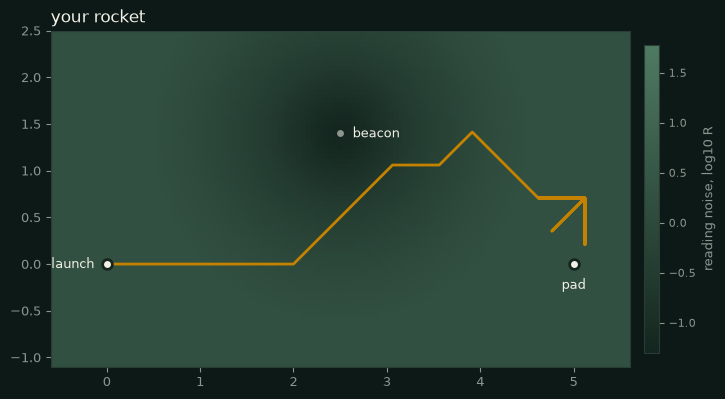

In [9]:
# @title Reference: task 2
import jax.numpy as jnp
from cpomdp import Agent, Belief, CallableSensor, LinearGaussianModel, Preference

from cpomdp_workshop import (
    LAUNCH,
    PAD,
    check_my_sensor,
    compass_planner,
    default_params,
    fly,
    plot_path,
)


def my_sensor(x, params):
    distance_squared = jnp.sum((x - params["beacon"]) ** 2)
    pull = params["beacon_gain"] * jnp.minimum(distance_squared, params["beacon_cap"])
    return jnp.eye(2) * (params["noise_floor"] + pull)


beacon_gain = 0.4
params = default_params(beacon_gain)
check_my_sensor(my_sensor, params)

curious_model = LinearGaussianModel(
    jnp.eye(2),
    control_matrix=jnp.eye(2),
    dynamics_noise=1e-3 * jnp.eye(2),
    prior=Belief(mean=LAUNCH, cov=4 * jnp.eye(2)),
    observation_model=CallableSensor(jnp.eye(2), my_sensor, params),
)
planner = compass_planner(curious_model)  # scores all nine compass moves every step
curious = Agent(curious_model, Preference(PAD, precision=jnp.eye(2)), selector=planner)
flight = fly(curious)
print(f"your k = {beacon_gain}")  # paste in chat
plot_path(flight, my_sensor, params)

k = 0.6, looking 1 ahead: stops 1.49 short


k = 0.6, looking 2 ahead: stops 1.65 short


k = 0.6, looking 3 ahead: stops 1.86 short


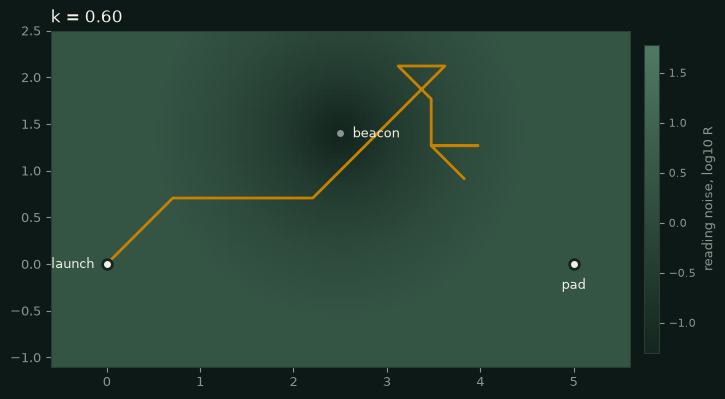

In [10]:
# @title Bonus: too curious to land
from cpomdp_workshop import (
    PAD,
    beacon_sensor,
    curious_rocket,
    default_params,
    fly,
    plot_path,
)

for horizon in (1, 2, 3):
    far = fly(curious_rocket(0.6, beacon_sensor, horizon=horizon))
    print(f"k = 0.6, looking {horizon} ahead: stops {far.distance_to(PAD):.2f} short")
plot_path(
    fly(curious_rocket(0.6, beacon_sensor)),
    beacon_sensor,
    default_params(0.6),
    title="k = 0.60",
)

In [11]:
# Checkpoint 2. Always run it. It puts the reference names in place.
import cpomdp_workshop as workshop

checkpoint = workshop.after_session_2()
globals().update(checkpoint)
print("restored:", ", ".join(checkpoint))

restored: model, rocket, report, my_sensor, beacon_gain, params, curious_model, planner, curious, flight


### Poll 2

At `k = 0.6` the rocket stops short of the pad, and looking further ahead does not
help. Why?

1. From near the beacon it cannot see the pad.
2. It still looks too few moves ahead.
3. It prefers a *reading* of the pad. At that `k` the pad reads so badly that a spot
   nearer the beacon is expected to read closer to "on the pad".
4. The thruster cost stops it.

<details><summary>Answer</summary>

3. The preference is over readings, and the expected miss includes the reading's own
noise. Where the noise is large, standing on the pad still reads far from it on
average. The curious rocket carries no thruster cost, so 4 cannot apply.

</details>

## Task 3 · the blackout

Put a blackout on the flight path. Near its centre the reading is swamped. There is a
rock in it, and no rocket models the rock.

Write the blackout term into `my_world`. Its height and width are read from `params`
for you. The slider sets `k` for your rocket.
`plot_world` flies three rockets past the rock: the 1960 rocket, yours and one at
`k = 0.20`.

Before the plot, the 1960 rocket runs on a second engine. `one_node` rewrites its
model as a graph of one node, the form cpomdp uses for branching models.
`check_backends` flies it on both.

**Paste max |difference| in chat.**

In [ ]:
import jax.numpy as jnp
from cpomdp import KalmanBackend

from cpomdp_workshop import check_backends, one_node, plot_world


def my_world(x, params):
    height, width = params["blackout_gain"], params["blackout_width"]
    from_blackout = jnp.sum((x - params["blackout"]) ** 2)
    blindness = ...  # height times jnp.exp of minus from_blackout over width
    return my_sensor(x, params) + jnp.eye(2) * blindness


beacon_gain = 0.08  # @param {type:"slider", min:0.02, max:0.4, step:0.02}

backend = ...  # task 1's model as a graph of one node
check_backends(KalmanBackend(model), backend)  # paste max |difference| in chat
plot_world(my_world, (0.0, beacon_gain, 0.20))

In [12]:
# @title Stuck on an error? The five most common, with their fixes
import cpomdp_workshop as workshop

workshop.symptoms()

1. a state-dependent sensor in the noise slot
   you wrote  LinearGaussianModel(I, observation_noise=sensor, control_matrix=I, dynamics_noise=1e-3 * I, prior=prior)
   cpomdp     TypeError: observation_noise takes a matrix, got CallableSensor, an ObservationModel. Pass it as observation_model.
   write      LinearGaussianModel(I, observation_model=sensor, control_matrix=I, dynamics_noise=1e-3 * I, prior=prior)



2. a goal beside a planner
   you wrote  Agent(curious_model, StateGoal(PAD), selector=planner)
   cpomdp     TypeError: selector= takes a Preference, the target and precision the selector chooses toward. Got StateGoal. A StateGoal or ObservationGoal configures the selector the Agent builds, so it goes without selector=.
   write      Agent(curious_model, Preference(PAD), selector=planner)



3. a state goal under a sensor that depends on the state
   you wrote  Agent(curious_model, StateGoal(PAD))
   cpomdp     ValueError: a StateGoal needs a fixed sensor. A state-dependent sensor would require converting the goal through C. Pass an ObservationGoal.
   write      Agent(curious_model, Preference(PAD), selector=planner)



4. a preference of the wrong length
   you wrote  Agent(curious_model, Preference([5.0, 0.0, 0.0]), selector=planner)
   cpomdp     ValueError: RecedingHorizonSelector reads the Preference's target as an observation, a vector of length 2, got shape (3,)
   write      Agent(curious_model, Preference([5.0, 0.0]), selector=planner)

5. swapping the model under a built rocket
   you wrote  rocket.model = model_with()
   cpomdp     AttributeError: property 'model' of 'Agent' object has no setter
   write      rocket = Agent(model_with(), pad_goal())



In [ ]:
# @title Hint 1
blindness = height * jnp.exp(-from_blackout / width)

In [ ]:
# @title Hint 2
backend = one_node(model)

KalmanBackend          mean (4.844446, 0.098086)   cov diagonal (0.006589, 0.006589)
CouplingGraphBackend   mean (4.844446, 0.098086)   cov diagonal (0.006589, 0.006589)
max |difference| = 7.1e-15


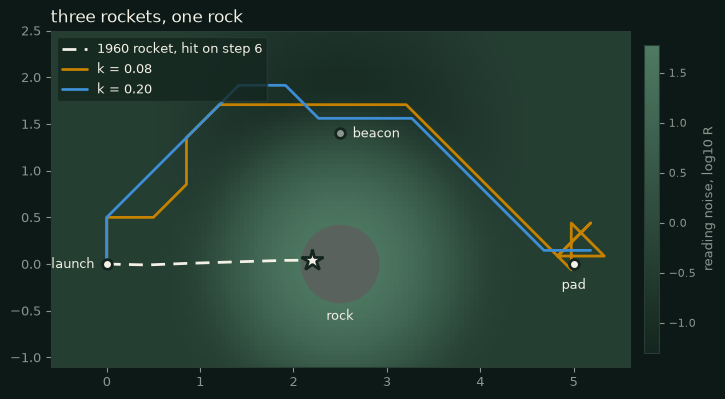

In [13]:
# @title Reference: task 3
import jax.numpy as jnp
from cpomdp import KalmanBackend

from cpomdp_workshop import check_backends, one_node, plot_world


def my_world(x, params):
    height, width = params["blackout_gain"], params["blackout_width"]
    from_blackout = jnp.sum((x - params["blackout"]) ** 2)
    blindness = height * jnp.exp(-from_blackout / width)
    return my_sensor(x, params) + jnp.eye(2) * blindness


beacon_gain = 0.08  # @param {type:"slider", min:0.02, max:0.4, step:0.02}

backend = one_node(model)
check_backends(KalmanBackend(model), backend)  # paste max |difference| in chat
plot_world(my_world, (0.0, beacon_gain, 0.20))

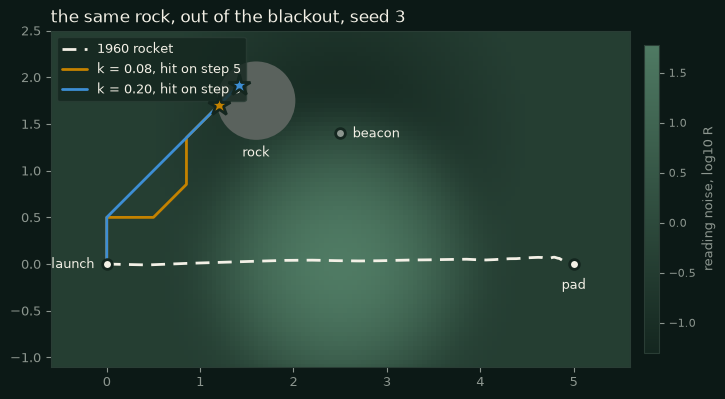

In [14]:
# @title Bonus: the same rock in clear sky
from cpomdp_workshop import CLEAR_SKY_ROCK, plot_world

plot_world(
    my_world,
    (0.0, beacon_gain, 0.20),
    hazard=CLEAR_SKY_ROCK,
    title="the same rock, out of the blackout, seed 3",
)

In [15]:
# Checkpoint 3. Always run it. It puts the reference names in place.
import cpomdp_workshop as workshop

checkpoint = workshop.after_session_3()
globals().update(checkpoint)
print("restored:", ", ".join(checkpoint))

restored: model, rocket, report, my_sensor, beacon_gain, params, curious_model, planner, curious, flight, my_world, backend


### Poll 3

Why did the curious rockets clear the rock in the blackout?

1. They modelled the rock.
2. They looked far enough ahead to see it coming.
3. A reading in the blackout is swamped, so a move into it is expected to read far
   from "on the pad". The rock sits in the blackout.
4. Luck. Another seed would hit it.

<details><summary>Answer</summary>

3. No rocket knows the rock is there, and each looks one move ahead. Where the noise
is large, a reading lands far from "on the pad" on average, so moves into the blackout
score badly. 4 is partly true. Over the first ten seeds the `k = 0.08` rocket clips the
rock twice and the `k = 0.20` rocket three times. The figure is seed 3. The bonus moves
the rock out of the blackout onto the seed 3 arc, and both curious rockets fly into it.

</details>

## Coda · what a printed number entitles you to say

Every step, the curious rocket scored all nine moves. Its certificate counts them.
The same search over five moves, seven deep, scores all 78125 plans.

The RxInfer oracle covers the fixed-noise case. Handed the curious model, it refuses
before Julia starts.

In [16]:
import cpomdp_workshop as workshop

print(curious.selector.certificate)
print(workshop.axis_certificate())
print(workshop.rxinfer_refusal(curious_model))

PROVED (set compass-9, |A|^H = 9^1 = 9, visited 9)


PROVED (set axis-5, |A|^H = 5^7 = 78125, visited 78125)
the model's observation_model is state-dependent; the RxInfer model filters on one fixed Q and R. Use KalmanBackend for R(x) or Q(x).


---

## Self-guided

Nothing below this line is run live. Each cell stands on the checkpoint above it.

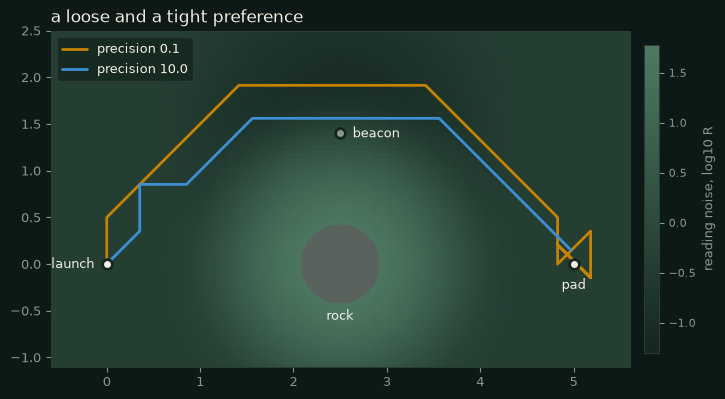

In [17]:
# @title How much the pad matters
import jax.numpy as jnp
from cpomdp import Agent, Preference

from cpomdp_workshop import (
    PAD,
    ROCK,
    compass_planner,
    default_params,
    fly,
    model_with,
    plot_flights,
    reference_sensor,
)

curious_model = model_with(reference_sensor, default_params(0.08))
flights = {}
for precision in (0.1, 10.0):
    preference = Preference(PAD, precision=precision * jnp.eye(2))
    rocket = Agent(curious_model, preference, selector=compass_planner(curious_model))
    flights[f"precision {precision}"] = fly(rocket, hazard=ROCK)
plot_flights(
    flights,
    reference_sensor,
    default_params(0.08),
    hazard=ROCK,
    title="a loose and a tight preference",
)

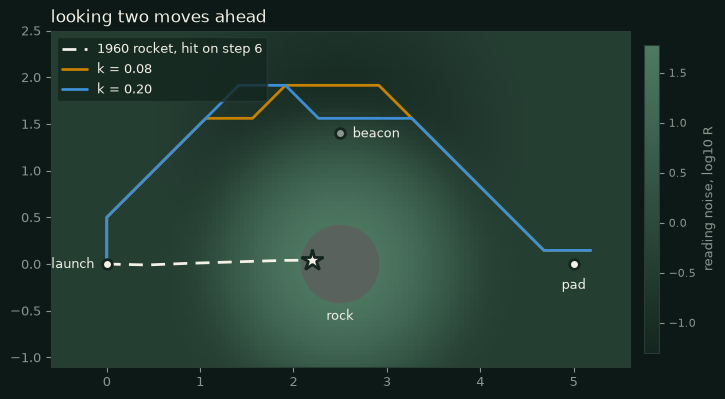

In [18]:
# @title Two moves ahead
from cpomdp_workshop import plot_world

plot_world(
    my_world, (0.0, beacon_gain, 0.20), horizon=2, title="looking two moves ahead"
)

In [19]:
# @title A model one filter cannot hold
from cpomdp_workshop import two_node_backend

try:
    two_node_backend().to_flat_model()
except Exception as refusal:
    print(f"{type(refusal).__name__}: {refusal}")

IncompatibleLinearizationError: Cannot flatten a state-dependent R(x) model with couplings: a mean-shifting coupling makes the prediction mean μ⁺ differ from the prior mean μ⁻, so no fixed linear-Gaussian model reproduces R(μ⁺). This reads the sensor's declared state-dependence; a declared R(x) that ignores the state is constant in fact and does flatten — see cpomdp.diagnostics.probe_model.
